In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import train_test_split,GridSearchCV,RandomizedSearchCV,HalvingGridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor,AdaBoostRegressor
from xgboost import XGBRegressor
from sklearn.neighbors import KNeighborsRegressor
import joblib

In [2]:
dt=pd.read_csv('crop_yield_dataset.csv')
dt

,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,North,Silt,Rice,949.026499,29.848902,True,True,Cloudy,145,8.652435
1,West,Sandy,Maize,999.896175,31.199774,True,True,Cloudy,84,8.277403
2,North,Chalky,Barley,338.868297,33.964042,True,True,Cloudy,74,4.310344
3,East,Sandy,Cotton,456.413345,30.197861,False,True,Rainy,104,4.366618
4,South,Clay,Soybean,230.489785,19.514573,False,True,Sunny,74,2.921209
...,...,...,...,...,...,...,...,...,...,...
29995,South,Clay,Barley,447.197137,25.264563,False,False,Cloudy,72,2.414513
29996,South,Peaty,Maize,120.167608,21.641270,False,True,Rainy,124,2.530323
29997,West,Clay,Soybean,188.328964,27.453966,False,True,Rainy,110,2.950646
29998,East,Silt,Maize,910.663454,25.925468,False,False,Cloudy,149,4.560514


## Data understanding

In [3]:
dt.tail()

,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
29995,South,Clay,Barley,447.197137,25.264563,False,False,Cloudy,72,2.414513
29996,South,Peaty,Maize,120.167608,21.641270,False,True,Rainy,124,2.530323
29997,West,Clay,Soybean,188.328964,27.453966,False,True,Rainy,110,2.950646
29998,East,Silt,Maize,910.663454,25.925468,False,False,Cloudy,149,4.560514
29999,East,Loam,Wheat,375.005982,38.929614,True,True,Cloudy,83,4.441381


In [4]:
dt.size

300000

In [5]:
dt.shape

(30000, 10)

In [6]:
dt.columns

Index(['Region', 'Soil_Type', 'Crop', 'Rainfall_mm', 'Temperature_Celsius',
       'Fertilizer_Used', 'Irrigation_Used', 'Weather_Condition',
       'Days_to_Harvest', 'Yield_tons_per_hectare'],
      dtype='object')

In [7]:
dt.dtypes 

Region                     object
Soil_Type                  object
Crop                       object
Rainfall_mm               float64
Temperature_Celsius       float64
Fertilizer_Used              bool
Irrigation_Used              bool
Weather_Condition          object
Days_to_Harvest             int64
Yield_tons_per_hectare    float64
dtype: object

In [8]:
dt.describe()

,Rainfall_mm,Temperature_Celsius,Days_to_Harvest,Yield_tons_per_hectare
count,30000.000000,30000.000000,30000.000000,30000.000000
mean,551.538027,27.580334,104.408067,4.666075
std,260.437084,7.223105,25.990715,1.692743
min,100.012778,15.002376,60.000000,-0.230392
25%,325.349768,21.309618,82.000000,3.438652
50%,552.850727,27.609667,104.000000,4.668101
75%,777.350133,33.859119,127.000000,5.892953
max,999.966975,39.998045,149.000000,9.590294


In [9]:
dt.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Region                  30000 non-null  object 
 1   Soil_Type               30000 non-null  object 
 2   Crop                    30000 non-null  object 
 3   Rainfall_mm             30000 non-null  float64
 4   Temperature_Celsius     30000 non-null  float64
 5   Fertilizer_Used         30000 non-null  bool   
 6   Irrigation_Used         30000 non-null  bool   
 7   Weather_Condition       30000 non-null  object 
 8   Days_to_Harvest         30000 non-null  int64  
 9   Yield_tons_per_hectare  30000 non-null  float64
dtypes: bool(2), float64(3), int64(1), object(4)
memory usage: 1.9+ MB


In [10]:
dt[['Fertilizer_Used','Irrigation_Used' ]].value_counts()

Fertilizer_Used  Irrigation_Used
False            False              7526
True             True               7519
False            True               7489
True             False              7466
Name: count, dtype: int64

## EDA

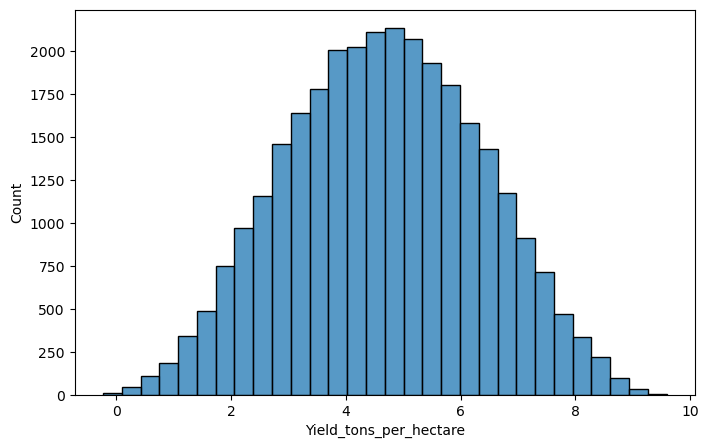

In [11]:
plt.figure(figsize=(8,5)) 
sns.histplot(dt['Yield_tons_per_hectare'],bins=30) 
plt.show()                                        

In [12]:
dt['Yield_tons_per_hectare'].describe()

count    30000.000000
mean         4.666075
std          1.692743
min         -0.230392
25%          3.438652
50%          4.668101
75%          5.892953
max          9.590294
Name: Yield_tons_per_hectare, dtype: float64

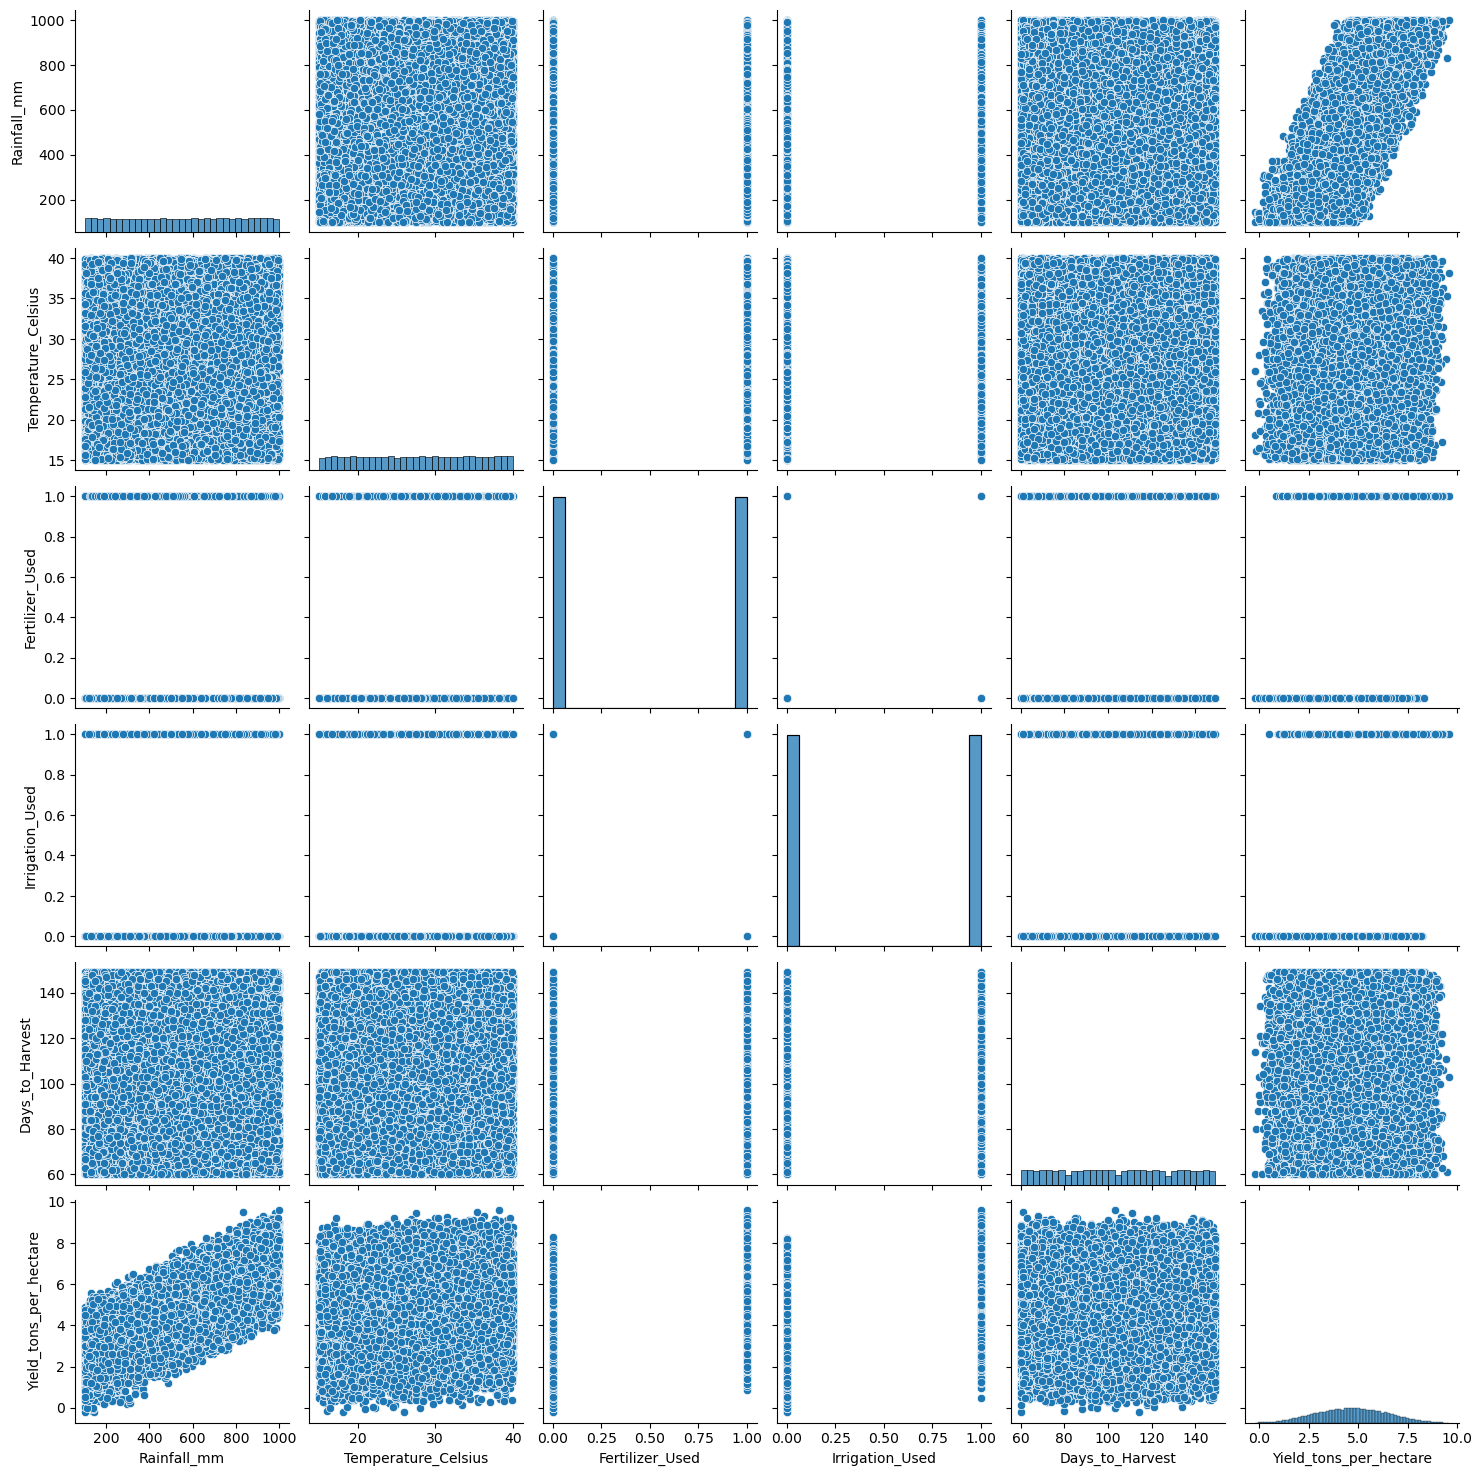

In [13]:
sns.pairplot(dt)
plt.show()

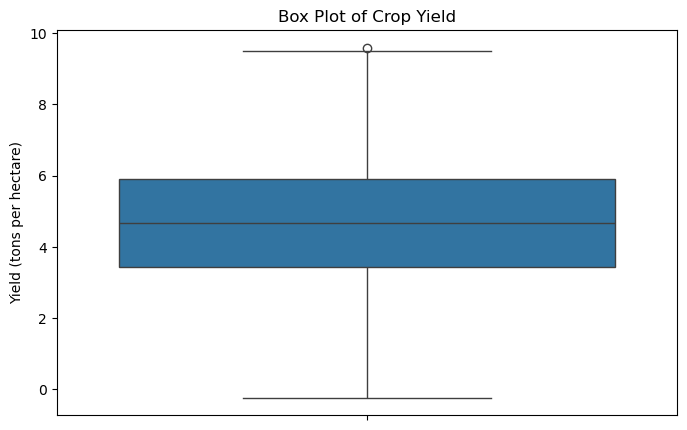

In [14]:
plt.figure(figsize=(8,5))
sns.boxplot(y=dt['Yield_tons_per_hectare'])
plt.title("Box Plot of Crop Yield")
plt.ylabel("Yield (tons per hectare)")
plt.show()

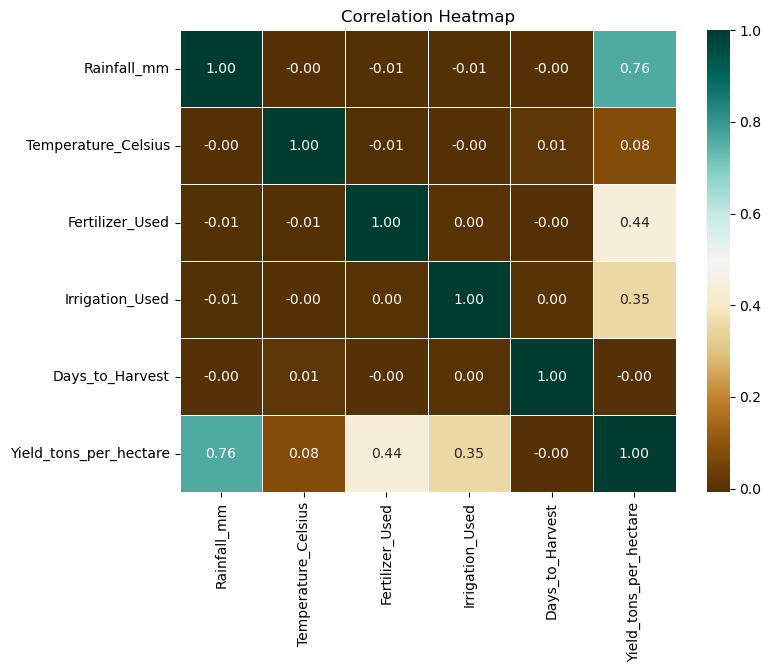

In [15]:
corr_mtx= dt.corr(numeric_only=True)
plt.figure(figsize=(8,6))
sns.heatmap(corr_mtx,annot=True,cmap='BrBG',fmt='.2f', linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

## Data Preprocessing

In [16]:
dt.isnull().sum()

Region                    0
Soil_Type                 0
Crop                      0
Rainfall_mm               0
Temperature_Celsius       0
Fertilizer_Used           0
Irrigation_Used           0
Weather_Condition         0
Days_to_Harvest           0
Yield_tons_per_hectare    0
dtype: int64

In [17]:
dt.isnull().sum().sum()

0

### outliers

In [18]:
numerical_columns = ['Rainfall_mm','Temperature_Celsius','Days_to_Harvest','Yield_tons_per_hectare']

for column in numerical_columns:
    Q1 = dt[column].quantile(0.25)
    Q3 = dt[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = dt[
        (dt[column] < lower_limit) |
        (dt[column] > upper_limit)
    ]
    
    print(column)
    print("Number of outliers:", len(outliers))
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print()

Rainfall_mm
Number of outliers: 0
Lower limit: -352.65078042503717
Upper limit: 1455.3506813827157

Temperature_Celsius
Number of outliers: 0
Lower limit: 2.485365184106321
Upper limit: 52.68337171792488

Days_to_Harvest
Number of outliers: 0
Lower limit: 14.5
Upper limit: 194.5

Yield_tons_per_hectare
Number of outliers: 1
Lower limit: -0.24279907177398874
Upper limit: 9.574403731838785



In [19]:
negative_yield = dt[dt['Yield_tons_per_hectare'] < 0]

print("Negative yield values:", len(negative_yield))

Negative yield values: 7


In [20]:
dt= dt[dt['Yield_tons_per_hectare'] >= 0]
dt

,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,North,Silt,Rice,949.026499,29.848902,True,True,Cloudy,145,8.652435
1,West,Sandy,Maize,999.896175,31.199774,True,True,Cloudy,84,8.277403
2,North,Chalky,Barley,338.868297,33.964042,True,True,Cloudy,74,4.310344
3,East,Sandy,Cotton,456.413345,30.197861,False,True,Rainy,104,4.366618
4,South,Clay,Soybean,230.489785,19.514573,False,True,Sunny,74,2.921209
...,...,...,...,...,...,...,...,...,...,...
29995,South,Clay,Barley,447.197137,25.264563,False,False,Cloudy,72,2.414513
29996,South,Peaty,Maize,120.167608,21.641270,False,True,Rainy,124,2.530323
29997,West,Clay,Soybean,188.328964,27.453966,False,True,Rainy,110,2.950646
29998,East,Silt,Maize,910.663454,25.925468,False,False,Cloudy,149,4.560514


## X,Y Seperate

In [21]:
X = dt.drop('Yield_tons_per_hectare', axis=1)

y = dt['Yield_tons_per_hectare']

In [22]:
X

,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest
0,North,Silt,Rice,949.026499,29.848902,True,True,Cloudy,145
1,West,Sandy,Maize,999.896175,31.199774,True,True,Cloudy,84
2,North,Chalky,Barley,338.868297,33.964042,True,True,Cloudy,74
3,East,Sandy,Cotton,456.413345,30.197861,False,True,Rainy,104
4,South,Clay,Soybean,230.489785,19.514573,False,True,Sunny,74
...,...,...,...,...,...,...,...,...,...
29995,South,Clay,Barley,447.197137,25.264563,False,False,Cloudy,72
29996,South,Peaty,Maize,120.167608,21.641270,False,True,Rainy,124
29997,West,Clay,Soybean,188.328964,27.453966,False,True,Rainy,110
29998,East,Silt,Maize,910.663454,25.925468,False,False,Cloudy,149


In [23]:
y

0        8.652435
1        8.277403
2        4.310344
3        4.366618
4        2.921209
           ...   
29995    2.414513
29996    2.530323
29997    2.950646
29998    4.560514
29999    4.441381
Name: Yield_tons_per_hectare, Length: 29993, dtype: float64

## train test split

In [24]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

## Label Encoding and scailing

In [25]:
categorical_columns = ["Region","Soil_Type","Crop","Weather_Condition"]

numerical_columns = ["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest"]

encoder = OneHotEncoder(handle_unknown="ignore",sparse_output=False)
scaler = StandardScaler()

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", encoder, categorical_columns),
        ("numerical", scaler, numerical_columns) 
    ],
    remainder="passthrough"
)

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

# Model building

## Linear regression

In [26]:
model = LinearRegression()

model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](24,)","[0.01,0. ,0. ,...,0. ,1.5 ,1.2 ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.319
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,24
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,20
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](24,)","[155.98,154.67,154.08,..., 0. , 0. , 0. ]"


In [27]:
lrtr = model.predict(X_train_scaled)
lrtr

array([6.5514013 , 3.55068527, 4.05815073, ..., 4.45488045, 4.96413434,
       3.80414767])

In [28]:
lr_xtrain_MAE= mean_absolute_error(y_train, lrtr)
lr_xtrain_MSE= mean_squared_error(y_train, lrtr)
lr_xtrain_RMSE= np.sqrt(mean_squared_error(y_train, lrtr))
lr_xtrain_R2= r2_score(y_train, lrtr)

print("xtrLR MAE:",lr_xtrain_MAE)
print("xtrLR MSE:",lr_xtrain_MSE) 
print("xtrLR RMSE:",lr_xtrain_RMSE) 
print("xtrLR R2 Score:",lr_xtrain_R2) 

xtrLR MAE: 0.4007035055317503
xtrLR MSE: 0.2515704001999858
xtrLR RMSE: 0.5015679417586273
xtrLR R2 Score: 0.9119371058345057


In [29]:
lrte= model.predict(X_test_scaled) # it contains both features abd also predict the target
lrte

array([4.80646867, 5.63676872, 5.95941246, ..., 5.73227987, 3.7494541 ,
       5.55688366])

In [30]:
lr_xtest_MAE= mean_absolute_error(y_test, lrte)
lr_xtest_MSE= mean_squared_error(y_test, lrte)
lr_xtest_RMSE= np.sqrt(mean_squared_error(y_test, lrte))
lr_xtest_R2= r2_score(y_test, lrte)

print("xteLR MAE:",lr_xtest_MAE)
print("xteLR MSE:",lr_xtest_MSE) 
print("xteLR RMSE:",lr_xtest_RMSE) 
print("xteLR R2 Score:",lr_xtest_R2) 

xteLR MAE: 0.3978967205875928
xteLR MSE: 0.250546251979707
xteLR RMSE: 0.5005459539140308
xteLR R2 Score: 0.9128970720041623


## Lasso Regression

In [31]:
model = Lasso(alpha=0.1)

model.fit(X_train_scaled, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [32]:
lstr = model.predict(X_train_scaled)
lstr

array([6.1518991 , 3.56250773, 4.45158466, ..., 4.40068137, 5.00030941,
       3.77399082])

In [33]:
ls_xtrain_MAE= mean_absolute_error(y_train, lstr)
ls_xtrain_MSE= mean_squared_error(y_train, lstr)
ls_xtrain_RMSE= np.sqrt(mean_squared_error(y_train, lstr))
ls_xtrain_R2= r2_score(y_train, lstr)

print("xtrLS MAE:",ls_xtrain_MAE)
print("xtrLS MSE:",ls_xtrain_MSE) 
print("xtrLS RMSE:",ls_xtrain_RMSE) 
print("xtrLS R2 Score:",ls_xtrain_R2) 

xtrLS MAE: 0.47517708034448447
xtrLS MSE: 0.3524927564635062
xtrLS RMSE: 0.5937110041623839
xtrLS R2 Score: 0.8766089640042205


In [34]:
lste= model.predict(X_test_scaled) 
lste

array([4.88665572, 5.23738899, 5.74797654, ..., 5.23801552, 3.74950286,
       5.38204449])

In [35]:
ls_xtest_MAE= mean_absolute_error(y_test, lste)
ls_xtest_MSE= mean_squared_error(y_test, lste)
ls_xtest_RMSE= np.sqrt(mean_squared_error(y_test, lste))
ls_xtest_R2= r2_score(y_test, lste)

print("xteLS MAE:",ls_xtest_MAE)
print("xteLS MSE:",ls_xtest_MSE) 
print("xteLS RMSE:",ls_xtest_RMSE) 
print("xteLS R2 Score:",ls_xtest_R2) 

xteLS MAE: 0.47411220392796816
xteLS MSE: 0.35316137302131273
xteLS RMSE: 0.5942738199023349
xteLS R2 Score: 0.8772227107684767


## Ridge Regression

In [36]:
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_scaled, y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [37]:
rdtr = ridge_model.predict(X_train_scaled)
rdtr

array([6.55115502, 3.55075206, 4.05834338, ..., 4.45487827, 4.96410678,
       3.80419747])

In [38]:
rd_xtrain_MAE= mean_absolute_error(y_train, rdtr)
rd_xtrain_MSE= mean_squared_error(y_train, rdtr)
rd_xtrain_RMSE= np.sqrt(mean_squared_error(y_train, rdtr))
rd_xtrain_R2= r2_score(y_train, rdtr)

print("xtrRD MAE:",rd_xtrain_MAE)
print("xtrRD MSE:",rd_xtrain_MSE) 
print("xtrRD RMSE:",rd_xtrain_RMSE) 
print("xtrRD R2 Score:",rd_xtrain_R2) 

xtrRD MAE: 0.4007035089915595
xtrRD MSE: 0.25157042901384763
xtrRD RMSE: 0.5015679704824139
xtrRD R2 Score: 0.911937095748136


In [39]:
rdte= model.predict(X_test_scaled) 
rdte

array([4.88665572, 5.23738899, 5.74797654, ..., 5.23801552, 3.74950286,
       5.38204449])

In [40]:
rd_xtest_MAE= mean_absolute_error(y_test, rdte)
rd_xtest_MSE= mean_squared_error(y_test, rdte)
rd_xtest_RMSE= np.sqrt(mean_squared_error(y_test, rdte))
rd_xtest_R2= r2_score(y_test, rdte)

print("xteRD MAE:",rd_xtest_MAE)
print("xteRD MSE:",rd_xtest_MSE) 
print("xteRD RMSE:",rd_xtest_RMSE) 
print("xteRD R2 Score:",rd_xtest_R2) 

xteRD MAE: 0.47411220392796816
xteRD MSE: 0.35316137302131273
xteRD RMSE: 0.5942738199023349
xteRD R2 Score: 0.8772227107684767


## Decision tree regressor

In [41]:
model = DecisionTreeRegressor(random_state=42,max_depth=10)

model.fit(X_train_scaled, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes ma

In [42]:
dttr = model.predict(X_train_scaled)
dttr

array([6.42861416, 3.71318404, 4.19520896, ..., 4.37455404, 4.93832831,
       4.21294802])

In [43]:
dt_xtrain_MAE= mean_absolute_error(y_train, dttr)
dt_xtrain_MSE= mean_squared_error(y_train, dttr)
dt_xtrain_RMSE= np.sqrt(mean_squared_error(y_train, dttr))
dt_xtrain_R2= r2_score(y_train, dttr)

print("xtrDT MAE:",dt_xtrain_MAE)
print("xtrDT MSE:",dt_xtrain_MSE) 
print("xtrDT RMSE:",dt_xtrain_RMSE) 
print("xtrDT R2 Score:",dt_xtrain_R2) 

xtrDT MAE: 0.35567806385594825
xtrDT MSE: 0.2029744461230883
xtrDT RMSE: 0.4505268539422354
xtrDT R2 Score: 0.9289482500603091


In [44]:
dtte = model.predict(X_test_scaled)
dtte

array([5.86016727, 5.71155984, 5.83822688, ..., 6.04155369, 3.58183213,
       5.61410521])

In [45]:
dt_xtest_MAE= mean_absolute_error(y_test, dtte)
dt_xtest_MSE= mean_squared_error(y_test, dtte)
dt_xtest_RMSE= np.sqrt(mean_squared_error(y_test, dtte))
dt_xtest_R2= r2_score(y_test, dtte)

print("xteDT MAE:",dt_xtest_MAE)
print("xteDT MSE:",dt_xtest_MSE) 
print("xteDT RMSE:",dt_xtest_RMSE) 
print("xteDT R2 Score:",dt_xtest_R2) 

xteDT MAE: 0.43673482284062115
xteDT MSE: 0.30495942994000763
xteDT RMSE: 0.5522313192313595
xteDT R2 Score: 0.8939802169945544


## Random forest regressor

In [46]:
rf = RandomForestRegressor(n_estimators=10,random_state=42)

rf.fit(X_train_scaled, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of

In [47]:
rftr = rf.predict(X_train_scaled)
rftr

array([6.6777246 , 3.77658148, 3.94518099, ..., 4.07583911, 4.79624555,
       4.54207148])

In [48]:
rf_xtrain_MAE= mean_absolute_error(y_train, rftr)
rf_xtrain_MSE= mean_squared_error(y_train, rftr)
rf_xtrain_RMSE= np.sqrt(mean_squared_error(y_train, rftr))
rf_xtrain_R2= r2_score(y_train, rftr)

print("xtrRF MAE:",rf_xtrain_MAE)
print("xtrRF MSE:",rf_xtrain_MSE) 
print("xtrRF RMSE:",rf_xtrain_RMSE) 
print("xtrRF R2 Score:",rf_xtrain_R2) 

xtrRF MAE: 0.17208574336260646
xtrRF MSE: 0.0532259202683423
xtrRF RMSE: 0.23070743435863159
xtrRF R2 Score: 0.9813681236754167


In [49]:
rfte = rf.predict(X_test_scaled)
rfte

array([4.76457474, 5.69460875, 5.9106833 , ..., 5.61767783, 3.31352694,
       5.48580894])

In [50]:
rf_xtest_MAE= mean_absolute_error(y_test, rfte)
rf_xtest_MSE= mean_squared_error(y_test, rfte)
rf_xtest_RMSE= np.sqrt(mean_squared_error(y_test, rfte))
rf_xtest_R2= r2_score(y_test, rfte)

print("xteRF MAE:",rf_xtest_MAE)
print("xteRF MSE:",rf_xtest_MSE) 
print("xteRF RMSE:",rf_xtest_RMSE) 
print("xteRF R2 Score:",rf_xtest_R2) 

xteRF MAE: 0.4345380261258023
xteRF MSE: 0.29896334237052213
xteRF RMSE: 0.5467754039553372
xteRF R2 Score: 0.8960647693664012


## AdaBoost Regressor

In [51]:
model = AdaBoostRegressor(random_state=42)

model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.In addition, it controls the bootstrap of the weights used to train the`estimator` at each boosting iteration.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.If ``None``, then the base estimator is:class:`~sklearn.tree.DecisionTreeRegressor` initialized with`max_depth=3`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",50
,"learning_rate learning_rate: float, default=1.0Weight applied to each regressor at each boosting iteration. A higherlearning rate increases the contribution of each regressor. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
,"loss loss: {'linear', 'square', 'exponential'}, default='linear'The loss function to use when updating the weights after eachboosting iteration.",'linear'
Name,Type,Value
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeRegressor,DecisionTreeR...r(max_depth=3)
estimator_errors_ estimator_errors_: ndarray of floatsRegression error for each estimator in the boosted ensemble.,"ndarray[float64](50,)","[0.24,0.22,0.26,...,0.34,0.29,0.32]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](50,)","[1.15,1.28,1.07,...,0.65,0.91,0.75]"
estimators_ estimators_: list of regressorsThe collection of fitted sub-estimators.,list,"[DecisionTreeR...te=1608637542), DecisionTreeR...ate=475813252), DecisionTreeR...ate=398267077), DecisionTreeR...ate=281053795), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](24,)","[0. ,0. ,0. ,...,0. ,0.19,0.14]"


In [52]:
abtr = model.predict(X_train_scaled)
abtr

array([6.48561022, 3.32420327, 4.22484964, ..., 4.94185543, 5.49989997,
       3.45175868])

In [53]:
ab_xtrain_MAE= mean_absolute_error(y_train, abtr)
ab_xtrain_MSE= mean_squared_error(y_train, abtr)
ab_xtrain_RMSE= np.sqrt(mean_squared_error(y_train, abtr))
ab_xtrain_R2= r2_score(y_train, abtr)

print("xtrAB MAE:",ab_xtrain_MAE)
print("xtrAB MSE:",ab_xtrain_MSE) 
print("xtrAB RMSE:",ab_xtrain_RMSE) 
print("xtrAB R2 Score:",ab_xtrain_R2) 

xtrAB MAE: 0.47907082377974575
xtrAB MSE: 0.3581134107828715
xtrAB RMSE: 0.5984257771711304
xtrAB R2 Score: 0.8746414388658352


In [54]:
abte = model.predict(X_test_scaled)
abte

array([5.46686119, 5.43442274, 5.838364  , ..., 5.43442274, 3.48269923,
       5.63577399])

In [55]:
ab_xtest_MAE= mean_absolute_error(y_test, abte)
ab_xtest_MSE= mean_squared_error(y_test, abte)
ab_xtest_RMSE= np.sqrt(mean_squared_error(y_test, abte))
ab_xtest_R2= r2_score(y_test, abte)

print("xteAB MAE:",ab_xtest_MAE)
print("xteAB MSE:",ab_xtest_MSE) 
print("xteAB RMSE:",ab_xtest_RMSE) 
print("xteAB R2 Score:",ab_xtest_R2) 

xteAB MAE: 0.48442113741302945
xteAB MSE: 0.3682034765242055
xteAB RMSE: 0.6067977229062461
xteAB R2 Score: 0.8719932920564996


## Gradient boosting Regressor

In [56]:
model = GradientBoostingRegressor(random_state=42)

model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf

In [57]:
gbtr= model.predict(X_train_scaled)
gbtr

array([6.48093413, 3.53219853, 4.07133221, ..., 4.38475175, 4.97791659,
       3.85094729])

In [58]:
gb_xtrain_MAE= mean_absolute_error(y_train, gbtr)
gb_xtrain_MSE= mean_squared_error(y_train, gbtr)
gb_xtrain_RMSE= np.sqrt(mean_squared_error(y_train, gbtr))
gb_xtrain_R2= r2_score(y_train, gbtr)

print("xtrGB MAE:",gb_xtrain_MAE)
print("xtrGB MSE:",gb_xtrain_MSE) 
print("xtrGB RMSE:",gb_xtrain_RMSE) 
print("xtrGB R2 Score:",gb_xtrain_R2) 

xtrGB MAE: 0.3964060831719565
xtrGB MSE: 0.24634859349716334
xtrGB RMSE: 0.4963351624629907
xtrGB R2 Score: 0.9137650132936415


In [59]:
gbte = model.predict(X_test_scaled)
gbte

array([4.69354586, 5.56553065, 5.93281871, ..., 5.71829864, 3.67665209,
       5.53178104])

In [60]:
gb_xtest_MAE= mean_absolute_error(y_test, gbte)
gb_xtest_MSE= mean_squared_error(y_test, gbte)
gb_xtest_RMSE= np.sqrt(mean_squared_error(y_test, gbte))
gb_xtest_R2= r2_score(y_test, gbte)

print("xteGB MAE:",gb_xtest_MAE)
print("xteGB MSE:",gb_xtest_MSE) 
print("xteGB RMSE:",gb_xtest_RMSE) 
print("xteGB R2 Score:",gb_xtest_R2) 

xteGB MAE: 0.40086459235844646
xteGB MSE: 0.2542515110442575
xteGB RMSE: 0.5042335877787769
xteGB R2 Score: 0.9116089309485474


## XGB Regressor

In [61]:
pip install xgboost

In [62]:
model = XGBRegressor(n_estimators=100,learning_rate=0.1,max_depth=6,random_state=42)

model.fit(X_train_scaled, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [63]:
xgbtr = model.predict(X_train_scaled)
xgbtr

array([6.397527 , 3.5598872, 3.985305 , ..., 4.355612 , 4.950051 ,
       3.8922   ], dtype=float32)

In [64]:
xgb_xtrain_MAE= mean_absolute_error(y_train, xgbtr)
xgb_xtrain_MSE= mean_squared_error(y_train, xgbtr)
xgb_xtrain_RMSE= np.sqrt(mean_squared_error(y_train, xgbtr))
xgb_xtrain_R2= r2_score(y_train, xgbtr)

print("xtrXGB MAE:",xgb_xtrain_MAE)
print("xtrXGB MSE:",xgb_xtrain_MSE) 
print("xtrXGB RMSE:",xgb_xtrain_RMSE) 
print("xtrXGB R2 Score:",xgb_xtrain_R2) 

xtrXGB MAE: 0.3685909207014825
xtrXGB MSE: 0.21369556704799586
xtrXGB RMSE: 0.4622721785355418
xtrXGB R2 Score: 0.9251952928896918


In [65]:
xgbte= model.predict(X_test_scaled)
xgbte

array([4.7763605, 5.5498767, 6.015571 , ..., 5.635674 , 3.6936734,
       5.6180162], dtype=float32)

In [66]:
xgb_xtest_MAE= mean_absolute_error(y_test, xgbte)
xgb_xtest_MSE= mean_squared_error(y_test, xgbte)
xgb_xtest_RMSE= np.sqrt(mean_squared_error(y_test, xgbte))
xgb_xtest_R2= r2_score(y_test, xgbte)

print("xteXGB MAE:",xgb_xtest_MAE)
print("xteXGB MSE:",xgb_xtest_MSE)
print("xteXGB RMSE:",xgb_xtest_RMSE)
print("xteXGB R2 Score:",xgb_xtest_R2) 

xteXGB MAE: 0.40557797316188715
xteXGB MSE: 0.26003808923671057
xteXGB RMSE: 0.5099392995609483
xteXGB R2 Score: 0.909597214949378


## KNN

#### knn

In [67]:
knn_regressor = KNeighborsRegressor(n_neighbors=5, algorithm='kd_tree', n_jobs=-1)

knn_regressor.fit(X_train_scaled, y_train)

,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'kd_tree'
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",-1
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [68]:
knntr = knn_regressor.predict(X_train_scaled)
knntr

array([6.43242176, 3.44250914, 3.91340001, ..., 3.6471803 , 4.39708576,
       3.68669207])

In [69]:
knn_xtrain_MAE= mean_absolute_error(y_train, knntr)
knn_xtrain_MSE= mean_squared_error(y_train, knntr)
knn_xtrain_RMSE= np.sqrt(mean_squared_error(y_train, knntr))
knn_xtrain_R2= r2_score(y_train, knntr)

print("xtrKNN MAE:",knn_xtrain_MAE)
print("xtrKNN MSE:",knn_xtrain_MSE) 
print("xtrKNN RMSE:",knn_xtrain_RMSE) 
print("xtrKNN R2 Score:",knn_xtrain_R2) 

xtrKNN MAE: 0.5470155973210988
xtrKNN MSE: 0.4673101697758201
xtrKNN RMSE: 0.6836008848559371
xtrKNN R2 Score: 0.8364168201397584


In [70]:
knnte = knn_regressor.predict(X_test_scaled)
knnte

array([4.82615932, 5.29863425, 6.31426864, ..., 5.20911651, 3.70876672,
       4.41874823])

In [71]:
knn_xtest_MAE= mean_absolute_error(y_test, knnte)
knn_xtest_MSE= mean_squared_error(y_test, knnte)
knn_xtest_RMSE= np.sqrt(mean_squared_error(y_test, knnte))
knn_xtest_R2= r2_score(y_test, knnte)

print("xteKNN MAE:",knn_xtest_MAE)
print("xteKNN MSE:",knn_xtest_MSE) 
print("xteKNN RMSE:",knn_xtest_RMSE) 
print("xteKNN R2 Score:",knn_xtest_R2) 

xteKNN MAE: 0.6587647981537883
xteKNN MSE: 0.6763490172876742
xteKNN RMSE: 0.822404412249639
xteKNN R2 Score: 0.7648658509661701


## score table

In [72]:
comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Lasso Regression',
        'Ridge Regression',
        'Decision Tree',
        'Random Forest',
        'AdaBoost',
        'Gradient Boost',
        'XGB Regressor',
        'KNN'
    ],
    'Train MAE':[
        lr_xtrain_MAE,
        ls_xtrain_MAE,
        rd_xtrain_MAE,
        dt_xtrain_MAE,
        rf_xtrain_MAE,
        ab_xtrain_MAE,
        gb_xtrain_MAE,
        xgb_xtrain_MAE,
        knn_xtrain_MAE
    ],
    'Test MAE':[
        lr_xtest_MAE,
        ls_xtest_MAE,
        rd_xtest_MAE,
        dt_xtest_MAE,
        rf_xtest_MAE,
        ab_xtest_MAE,
        gb_xtest_MAE,
        xgb_xtest_MAE,
        knn_xtest_MAE
    ],
    'Train MSE':[
        lr_xtrain_MSE,
        ls_xtrain_MSE,
        rd_xtrain_MSE,
        dt_xtrain_MSE,
        rf_xtrain_MSE,
        ab_xtrain_MSE,
        gb_xtrain_MSE,
        xgb_xtrain_MSE,
        knn_xtrain_MSE
    ],
    'Test MSE':[
        lr_xtest_MSE,
        ls_xtest_MSE,
        rd_xtest_MSE,
        dt_xtest_MSE,
        rf_xtest_MSE,
        ab_xtest_MSE,
        gb_xtest_MSE,
        xgb_xtest_MSE,
        knn_xtest_MSE
    ],
    'Train RMSE':[
        lr_xtrain_RMSE,
        ls_xtrain_RMSE,
        rd_xtrain_RMSE,
        dt_xtrain_RMSE,
        rf_xtrain_RMSE,
        ab_xtrain_RMSE,
        gb_xtrain_RMSE,
        xgb_xtrain_RMSE,
        knn_xtrain_RMSE
    ],
    'Test RMSE':[
        lr_xtest_RMSE,
        ls_xtest_RMSE,
        rd_xtest_RMSE,
        dt_xtest_RMSE,
        rf_xtest_RMSE,
        ab_xtest_RMSE,
        gb_xtest_RMSE,
        xgb_xtest_RMSE,
        knn_xtest_RMSE
    ],
    'Train R2':[
        lr_xtrain_R2,
        ls_xtrain_R2,
        rd_xtrain_R2,
        dt_xtrain_R2,
        rf_xtrain_R2,
        ab_xtrain_R2,
        gb_xtrain_R2,
        xgb_xtrain_R2,
        knn_xtrain_R2
    ],
    'Test R2':[
        lr_xtest_R2,
        ls_xtest_R2,
        rd_xtest_R2,
        dt_xtest_R2,
        rf_xtest_R2,
        ab_xtest_R2,
        gb_xtest_R2,
        xgb_xtest_R2,
        knn_xtest_R2
    ]
})
comparison   

,Model,Train MAE,Test MAE,Train MSE,Test MSE,Train RMSE,Test RMSE,Train R2,Test R2
0,Linear Regression,0.400704,0.397897,0.251570,0.250546,0.501568,0.500546,0.911937,0.912897
1,Lasso Regression,0.475177,0.474112,0.352493,0.353161,0.593711,0.594274,0.876609,0.877223
2,Ridge Regression,0.400704,0.474112,0.251570,0.353161,0.501568,0.594274,0.911937,0.877223
3,Decision Tree,0.355678,0.436735,0.202974,0.304959,0.450527,0.552231,0.928948,0.893980
4,Random Forest,0.172086,0.434538,0.053226,0.298963,0.230707,0.546775,0.981368,0.896065
5,AdaBoost,0.479071,0.484421,0.358113,0.368203,0.598426,0.606798,0.874641,0.871993
6,Gradient Boost,0.396406,0.400865,0.246349,0.254252,0.496335,0.504234,0.913765,0.911609
7,XGB Regressor,0.368591,0.405578,0.213696,0.260038,0.462272,0.509939,0.925195,0.909597
8,KNN,0.547016,0.658765,0.467310,0.676349,0.683601,0.822404,0.836417,0.764866


In [73]:
compare = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Lasso Regression',
        'Ridge Regression',
        'Decision Tree',
        'Random Forest',
        'AdaBoost',
        'Gradient Boost',
        'XGB Regressor',
        'KNN'
    ],

     'Train R2':[
        lr_xtrain_R2,
        ls_xtrain_R2,
        rd_xtrain_R2,
        dt_xtrain_R2,
        rf_xtrain_R2,
        ab_xtrain_R2,
        gb_xtrain_R2,
        xgb_xtrain_R2,
        knn_xtrain_R2
    ],
    
     'Test R2':[
        lr_xtest_R2,
        ls_xtest_R2,
        rd_xtest_R2,
        dt_xtest_R2,
        rf_xtest_R2,
        ab_xtest_R2,
        gb_xtest_R2,
        xgb_xtest_R2,
        knn_xtest_R2
    ]
})
compare

,Model,Train R2,Test R2
0,Linear Regression,0.911937,0.912897
1,Lasso Regression,0.876609,0.877223
2,Ridge Regression,0.911937,0.877223
3,Decision Tree,0.928948,0.893980
4,Random Forest,0.981368,0.896065
5,AdaBoost,0.874641,0.871993
6,Gradient Boost,0.913765,0.911609
7,XGB Regressor,0.925195,0.909597
8,KNN,0.836417,0.764866


# hyper parameter tuning

## Linear Regression

In [74]:
model = LinearRegression()

model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](24,)","[0.01,0. ,0. ,...,0. ,1.5 ,1.2 ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.319
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,24
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,20
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](24,)","[155.98,154.67,154.08,..., 0. , 0. , 0. ]"


In [75]:
tulrtr = model.predict(X_train_scaled)
tulrtr

array([6.5514013 , 3.55068527, 4.05815073, ..., 4.45488045, 4.96413434,
       3.80414767])

In [76]:
tulr_xtrain_MAE= mean_absolute_error(y_train, tulrtr)
tulr_xtrain_MSE= mean_squared_error(y_train, tulrtr)
tulr_xtrain_RMSE= np.sqrt(mean_squared_error(y_train, tulrtr))
tulr_xtrain_R2= r2_score(y_train, tulrtr)

print("TxtrLR MAE:",tulr_xtrain_MAE)
print("TxtrLR MSE:",tulr_xtrain_MSE) 
print("TxtrLR RMSE:",tulr_xtrain_RMSE) 
print("TxtrLR R2 Score:",tulr_xtrain_R2) 

TxtrLR MAE: 0.4007035055317503
TxtrLR MSE: 0.2515704001999858
TxtrLR RMSE: 0.5015679417586273
TxtrLR R2 Score: 0.9119371058345057


In [77]:
tulrte= model.predict(X_test_scaled) # it contains both features abd also predict the target
tulrte

array([4.80646867, 5.63676872, 5.95941246, ..., 5.73227987, 3.7494541 ,
       5.55688366])

In [78]:
tulr_xtest_MAE= mean_absolute_error(y_test, tulrte)
tulr_xtest_MSE= mean_squared_error(y_test, tulrte)
tulr_xtest_RMSE= np.sqrt(mean_squared_error(y_test, tulrte))
tulr_xtest_R2= r2_score(y_test, tulrte)

print("TxteLR MAE:",tulr_xtest_MAE)
print("TxteLR MSE:",tulr_xtest_MSE) 
print("TxteLR RMSE:",tulr_xtest_RMSE) 
print("TxteLR R2 Score:",tulr_xtest_R2) 

TxteLR MAE: 0.3978967205875928
TxteLR MSE: 0.250546251979707
TxteLR RMSE: 0.5005459539140308
TxteLR R2 Score: 0.9128970720041623


## Lasso Regression

In [79]:
lasso = Lasso(max_iter=10000)


param_grid = {
    'alpha': [0.001, 0.01, 0.1, 1, 10, 100]
}

tune_lasso= GridSearchCV(
    estimator=lasso,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)


tune_lasso.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Lasso(max_iter=10000)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalue

In [80]:
print("Best Alpha:", tune_lasso.best_params_)

Best Alpha: {'alpha': 0.001}


In [81]:
print("Best score:",tune_lasso.best_score_)

Best score: 0.9118127211189837


In [82]:
best_lasso = tune_lasso.best_estimator_ 

In [83]:
tulstr = best_lasso.predict(X_train_scaled)
tulstr

array([6.54913735, 3.55513457, 4.06171329, ..., 4.46257493, 4.96616112,
       3.79885884])

In [84]:
tuls_xtrain_MAE= mean_absolute_error(y_train, tulstr)
tuls_xtrain_MSE= mean_squared_error(y_train, tulstr)
tuls_xtrain_RMSE= np.sqrt(mean_squared_error(y_train, tulstr))
tuls_xtrain_R2= r2_score(y_train, tulstr)

print("TxtrLS MAE:",tuls_xtrain_MAE)
print("TxtrLS MSE:",tuls_xtrain_MSE) 
print("TxtrLS RMSE:",tuls_xtrain_RMSE) 
print("TxtrLS R2 Score:",tuls_xtrain_R2) 

TxtrLS MAE: 0.40068918598362013
TxtrLS MSE: 0.2516336007127868
TxtrLS RMSE: 0.5016309407450729
TxtrLS R2 Score: 0.9119149823252789


In [85]:
tulste= best_lasso.predict(X_test_scaled) 
tulste

array([4.79048182, 5.63747245, 5.94143159, ..., 5.73784591, 3.7374132 ,
       5.55456106])

In [86]:
tuls_xtest_MAE= mean_absolute_error(y_test, tulste)
tuls_xtest_MSE= mean_squared_error(y_test, tulste)
tuls_xtest_RMSE= np.sqrt(mean_squared_error(y_test, tulste))
tuls_xtest_R2= r2_score(y_test, tulste)

print("TxteLS MAE:",tuls_xtest_MAE)
print("TxteLS MSE:",tuls_xtest_MSE) 
print("TxteLS RMSE:",tuls_xtest_RMSE) 
print("TxteLS R2 Score:",tuls_xtest_R2) 

TxteLS MAE: 0.39797367483230883
TxteLS MSE: 0.2505775809208123
TxteLS RMSE: 0.5005772477058983
TxteLS R2 Score: 0.9128861804323278


## Ridge Regression

In [87]:
ridge = Ridge()


param_grid = {
    'alpha': [0.01, 0.1, 1, 10, 100, 1000]
}


tune_ridge = GridSearchCV(
    ridge,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)


tune_ridge.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Ridge()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more 

In [88]:
print("Best Alpha:", tune_ridge.best_params_)

Best Alpha: {'alpha': 1}


In [89]:
print("Best score:",tune_ridge.best_score_)

Best score: 0.9117800179501987


In [90]:
best_ridge = tune_ridge.best_estimator_

In [91]:
turdtr = best_ridge.predict(X_train_scaled)
turdtr

array([6.55115502, 3.55075206, 4.05834338, ..., 4.45487827, 4.96410678,
       3.80419747])

In [92]:
turd_xtrain_MAE= mean_absolute_error(y_train, turdtr)
turd_xtrain_MSE= mean_squared_error(y_train, turdtr)
turd_xtrain_RMSE= np.sqrt(mean_squared_error(y_train, turdtr))
turd_xtrain_R2= r2_score(y_train, turdtr)

print("TxtrRD MAE:",turd_xtrain_MAE)
print("TxtrRD MSE:",turd_xtrain_MSE) 
print("TxtrRD RMSE:",turd_xtrain_RMSE) 
print("TxtrRD R2 Score:",turd_xtrain_R2) 

TxtrRD MAE: 0.4007035089915595
TxtrRD MSE: 0.25157042901384763
TxtrRD RMSE: 0.5015679704824139
TxtrRD R2 Score: 0.911937095748136


In [93]:
turdte= best_ridge.predict(X_test_scaled)
turdte

array([4.80643778, 5.63656219, 5.95933306, ..., 5.73206891, 3.74947088,
       5.55686368])

In [94]:
turd_xtest_MAE= mean_absolute_error(y_test, turdte)
turd_xtest_MSE= mean_squared_error(y_test, turdte)
turd_xtest_RMSE= np.sqrt(mean_squared_error(y_test, turdte))
turd_xtest_R2= r2_score(y_test, turdte)

print("TxteRD MAE:",turd_xtest_MAE)
print("TxteRD MSE:",turd_xtest_MSE) 
print("TxteRD RMSE:",turd_xtest_RMSE) 
print("TxteRD R2 Score:",turd_xtest_R2) 

TxteRD MAE: 0.3978970515127389
TxteRD MSE: 0.2505468738735626
TxteRD RMSE: 0.5005465751291908
TxteRD R2 Score: 0.912896855801464


## Decision tree regressor

In [95]:
dt = DecisionTreeRegressor(random_state=42)

param_grid_dt = {
    'max_depth': [3, 5, 8, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': [None, 'sqrt', 'log2']
}

tune_dt= RandomizedSearchCV(
    estimator=dt,
    param_distributions=param_grid_dt,
    n_iter=10,
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1,
)

tune_dt.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeR...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [3, 5, ...], 'max_features': [None, 'sqrt', ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for mult

In [96]:
print("Best Parameters:",tune_dt.best_params_)

Best Parameters: {'min_samples_split': 10, 'min_samples_leaf': 8, 'max_features': None, 'max_depth': 8}


In [97]:
print("Best score:",tune_dt.best_score_)

Best score: 0.9034722728216537


In [98]:
best_dt = tune_dt.best_estimator_

In [99]:
tudttr = best_dt.predict(X_train_scaled)
tudttr

array([6.49641951, 3.70181877, 4.21512004, ..., 4.53437191, 5.05553583,
       3.7964561 ])

In [100]:
tudt_xtrain_MAE= mean_absolute_error(y_train, tudttr)
tudt_xtrain_MSE= mean_squared_error(y_train, tudttr)
tudt_xtrain_RMSE= np.sqrt(mean_squared_error(y_train, tudttr))
tudt_xtrain_R2= r2_score(y_train, tudttr)

print("TxtrDT MAE:",tudt_xtrain_MAE)
print("TxtrDT MSE:",tudt_xtrain_MSE) 
print("TxtrDT RMSE:",tudt_xtrain_RMSE) 
print("TxtrDT R2 Score:",tudt_xtrain_R2) 

TxtrDT MAE: 0.39033162334992977
TxtrDT MSE: 0.23920033100847793
TxtrDT RMSE: 0.48908110882396383
TxtrDT R2 Score: 0.9162672817739868


In [101]:
tudtte = best_dt.predict(X_test_scaled)
tudtte

array([4.83064286, 5.83287929, 5.77465875, ..., 5.83287929, 3.69566793,
       5.64930208])

In [102]:
tudt_xtest_MAE= mean_absolute_error(y_test, tudtte)
tudt_xtest_MSE= mean_squared_error(y_test, tudtte)
tudt_xtest_RMSE= np.sqrt(mean_squared_error(y_test, tudtte))
tudt_xtest_R2= r2_score(y_test, tudtte)

print("TxteDT MAE:",tudt_xtest_MAE)
print("TxteDT MSE:",tudt_xtest_MSE) 
print("TxteDT RMSE:",tudt_xtest_RMSE) 
print("TxteDT R2 Score:",tudt_xtest_R2)

TxteDT MAE: 0.41186703343904973
TxteDT MSE: 0.26859131626551597
TxteDT RMSE: 0.5182579630507533
TxteDT R2 Score: 0.9066236677015731


## Random forest regressor

In [103]:
rf = RandomForestRegressor(random_state=42,n_jobs=-1)

param_grid = {
    'n_estimators': [100, 150, 200],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 0.7, 1.0]
}

tune_rf = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1,
)

tune_rf.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [10, 15, ...], 'max_features': ['sqrt', 0.7, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also fo

In [104]:
print("Best Parameters:",tune_rf.best_params_)

Best Parameters: {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 0.7, 'max_depth': 15}


In [105]:
print("Best CV R2 Score:",tune_rf.best_score_)

Best CV R2 Score: 0.9069227221597798


In [106]:
best_rf = tune_rf.best_estimator_

In [107]:
turftr = best_rf.predict(X_train_scaled)
turftr

array([6.54577239, 3.71382726, 4.03730141, ..., 4.14897133, 4.74990669,
       4.0500854 ])

In [108]:
turf_xtrain_MAE= mean_absolute_error(y_train, turftr)
turf_xtrain_MSE= mean_squared_error(y_train, turftr)
turf_xtrain_RMSE= np.sqrt(mean_squared_error(y_train, turftr))
turf_xtrain_R2= r2_score(y_train, turftr)

print("TxtrRF MAE:",turf_xtrain_MAE)
print("TxtrRF MSE:",turf_xtrain_MSE) 
print("TxtrRF RMSE:",turf_xtrain_RMSE) 
print("TxtrRF R2 Score:",turf_xtrain_R2) 

TxtrRF MAE: 0.28752029733180423
TxtrRF MSE: 0.13316571304476235
TxtrRF RMSE: 0.36491877595536565
TxtrRF R2 Score: 0.9533849845410622


In [109]:
turfte = best_rf.predict(X_test_scaled)
turfte

array([4.96520505, 5.59054828, 5.89259612, ..., 5.7498376 , 3.54355439,
       5.45892114])

In [110]:
turf_xtest_MAE= mean_absolute_error(y_test, turfte)
turf_xtest_MSE= mean_squared_error(y_test, turfte)
turf_xtest_RMSE= np.sqrt(mean_squared_error(y_test, turfte))
turf_xtest_R2= r2_score(y_test, turfte)

print("TxteRF MAE:",turf_xtest_MAE)
print("TxteRF MSE:",turf_xtest_MSE) 
print("TxteRF RMSE:",turf_xtest_RMSE) 
print("TxteRF R2 Score:",turf_xtest_R2) 

TxteRF MAE: 0.41010808633769213
TxteRF MSE: 0.2653695653980999
TxteRF RMSE: 0.5151403356349606
TxteRF R2 Score: 0.9077437161222048


## AdaBoost Regressor

In [111]:
base_model = DecisionTreeRegressor(max_depth=4,min_samples_leaf=5,random_state=42)

param_grid = {
    'n_estimators':[10,20],
    'learning_rate': [0.01, 0.05, 0.1],
    'loss': ['linear', 'square']
}
tune_ada = GridSearchCV(
    estimator=AdaBoostRegressor(estimator=base_model, random_state=42),
    param_grid=param_grid,
    cv=5,
    n_jobs=-1
)
tune_ada.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",AdaBoostRegre...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.01, 0.05, ...], 'loss': ['linear', 'square'], 'n_estimators': [10, 20]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Contro

In [112]:
print("Best Parameters:",tune_ada.best_params_)

Best Parameters: {'learning_rate': 0.1, 'loss': 'square', 'n_estimators': 20}


In [113]:
print("Best Score:",tune_ada.best_score_)

Best Score: 0.8814441590657373


In [114]:
best_ada =tune_ada.best_estimator_

In [115]:
tuabtr = best_ada.predict(X_train_scaled)
tuabtr

array([6.61542626, 3.82424075, 3.8982802 , ..., 4.12693875, 5.30262875,
       3.92092432])

In [116]:

tuab_xtrain_MAE= mean_absolute_error(y_train, tuabtr)
tuab_xtrain_MSE= mean_squared_error(y_train, tuabtr)
tuab_xtrain_RMSE= np.sqrt(mean_squared_error(y_train, tuabtr))
tuab_xtrain_R2= r2_score(y_train, tuabtr)

print("TxtrAB MAE:",tuab_xtrain_MAE)
print("TxtrAB MSE:",tuab_xtrain_MSE) 
print("TxtrAB RMSE:",tuab_xtrain_RMSE) 
print("TxtrAB R2 Score:",tuab_xtrain_R2) 

TxtrAB MAE: 0.4598809766611879
TxtrAB MSE: 0.32957466978011724
TxtrAB RMSE: 0.5740859428518671
TxtrAB R2 Score: 0.8846315017927302


In [117]:
tuabte = best_ada.predict(X_test_scaled)
tuabte

array([5.11913727, 5.40197514, 5.53876819, ..., 5.40197514, 3.96480297,
       5.1408286 ])

In [118]:
tuab_xtest_MAE= mean_absolute_error(y_test, tuabte)
tuab_xtest_MSE= mean_squared_error(y_test, tuabte)
tuab_xtest_RMSE= np.sqrt(mean_squared_error(y_test, tuabte))
tuab_xtest_R2= r2_score(y_test, tuabte)

print("TxteAB MAE:",tuab_xtest_MAE)
print("TxteAB MSE:",tuab_xtest_MSE) 
print("TxteAB RMSE:",tuab_xtest_RMSE) 
print("TxteAB R2 Score:",tuab_xtest_R2) 

TxteAB MAE: 0.46213200919060493
TxteAB MSE: 0.33458234828243544
TxteAB RMSE: 0.5784309364845862
TxteAB R2 Score: 0.88368174753824


## Gradient Boosting regressor

In [119]:

gbr = GradientBoostingRegressor(n_iter_no_change=10,validation_fraction=0.1,random_state=42)

param_grid = {
    'n_estimators': [100, 150, 200],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [2, 3, 4],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2, 4],
    'subsample': [0.8, 1.0]
}


tune_gb = RandomizedSearchCV(
    estimator=gbr,
    param_distributions=param_grid,
    n_iter=10,             
    scoring='r2',
    cv=3,
    random_state=42,
    n_jobs=-1
)

tune_gb.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GradientBoost...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'learning_rate': [0.03, 0.05, ...], 'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multi

In [120]:
print("Best Parameters:",tune_gb.best_params_)

Best Parameters: {'subsample': 1.0, 'n_estimators': 150, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 2, 'learning_rate': 0.1}


In [121]:
print("Best Score:",tune_gb.best_score_)

Best Score: 0.9109386298292147


In [122]:
best_gbr = tune_gb.best_estimator_

In [123]:
tugbtr= best_gbr.predict(X_train_scaled)
tugbtr

array([6.4622739 , 3.57651292, 4.12975373, ..., 4.49126558, 4.9279973 ,
       3.74217112])

In [124]:
tugb_xtrain_MAE= mean_absolute_error(y_train, tugbtr)
tugb_xtrain_MSE= mean_squared_error(y_train, tugbtr)
tugb_xtrain_RMSE= np.sqrt(mean_squared_error(y_train, tugbtr))
tugb_xtrain_R2= r2_score(y_train, tugbtr)

print("TxteGB MAE:",tugb_xtrain_MAE)
print("TxteGB MSE:",tugb_xtrain_MSE) 
print("TxteGB RMSE:",tugb_xtrain_RMSE) 
print("TxteGB R2 Score:",tugb_xtrain_R2) 

TxteGB MAE: 0.3988371159096968
TxteGB MSE: 0.2489861687231324
TxteGB RMSE: 0.4989851387798362
TxteGB R2 Score: 0.912841723002759


In [125]:
tugbte = best_gbr.predict(X_test_scaled)
tugbte

array([4.83985574, 5.54781904, 5.9176795 , ..., 5.7152048 , 3.74499598,
       5.52901841])

In [126]:
tugb_xtest_MAE= mean_absolute_error(y_test, tugbte)
tugb_xtest_MSE= mean_squared_error(y_test, tugbte)
tugb_xtest_RMSE= np.sqrt(mean_squared_error(y_test, tugbte))
tugb_xtest_R2= r2_score(y_test, tugbte)

print("TxteGB MAE:",tugb_xtest_MAE)
print("TxteGB MSE:",tugb_xtest_MSE) 
print("TxteGB RMSE:",tugb_xtest_RMSE) 
print("TxteGB R2 Score:",tugb_xtest_R2) 

TxteGB MAE: 0.40088921587594245
TxteGB MSE: 0.2540434037698535
TxteGB RMSE: 0.5040271855464281
TxteGB R2 Score: 0.9116812798773164


## XGB Regressor

In [127]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [128]:

xgb = XGBRegressor(
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1,
    tree_method='hist'
)

param_grid = {
    'n_estimators': [200, 300, 400],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.03, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'min_child_weight': [1, 3, 5],
    'reg_alpha': [0, 0.1],
    'reg_lambda': [2,5]
}

tune_xgb= RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_grid,
    n_iter=10,         
    scoring='r2',
    cv=3,              
    random_state=42,
    n_jobs=-1,
)

tune_xgb.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.03, 0.05, ...], 'max_depth': [3, 4, ...], 'min_child_weight': [1, 3, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for 

In [129]:
print("Best Parameters:",tune_xgb.best_params_)

Best Parameters: {'subsample': 1.0, 'reg_lambda': 2, 'reg_alpha': 0, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.8}


In [130]:
print("Best score:",tune_xgb.best_score_)

Best score: 0.9106556347545455


In [131]:
best_xgb = tune_xgb.best_estimator_

In [132]:
tuxgbtr = best_xgb.predict(X_train_scaled)
tuxgbtr

array([6.513311 , 3.562802 , 4.1041045, ..., 4.4994836, 4.980692 ,
       3.8140702], dtype=float32)

In [133]:
tuxgb_xtrain_MAE= mean_absolute_error(y_train, tuxgbtr)
tuxgb_xtrain_MSE= mean_squared_error(y_train, tuxgbtr)
tuxgb_xtrain_RMSE= np.sqrt(mean_squared_error(y_train, tuxgbtr))
tuxgb_xtrain_R2= r2_score(y_train, tuxgbtr)

print("TxtrXGB MAE:",tuxgb_xtrain_MAE)
print("TxtrXGB MSE:",tuxgb_xtrain_MSE) 
print("TxtrXGB RMSE:",tuxgb_xtrain_RMSE) 
print("TxtrXGB R2 Score:",tuxgb_xtrain_R2) 

TxtrXGB MAE: 0.39637352131531034
TxtrXGB MSE: 0.24622616877816442
TxtrXGB RMSE: 0.49621181845877516
TxtrXGB R2 Score: 0.9138078683952904


In [134]:
tuxgbte= best_xgb.predict(X_test_scaled)
tuxgbte

array([4.751319 , 5.5844417, 5.9321017, ..., 5.6864715, 3.6945581,
       5.54746  ], dtype=float32)

In [135]:
tuxgb_xtest_MAE= mean_absolute_error(y_test, tuxgbte)
tuxgb_xtest_MSE= mean_squared_error(y_test, tuxgbte)
tuxgb_xtest_RMSE= np.sqrt(mean_squared_error(y_test, tuxgbte))
tuxgb_xtest_R2= r2_score(y_test, tuxgbte)

print("TxteXGB MAE:",tuxgb_xtest_MAE)
print("TxteXGB MSE:",tuxgb_xtest_MSE)
print("TxteXGB RMSE:",tuxgb_xtest_RMSE)
print("TxteXGB R2 Score:",tuxgb_xtest_R2) 

TxteXGB MAE: 0.4005977162759101
TxteXGB MSE: 0.2541464108793196
TxteXGB RMSE: 0.504129359271328
TxteXGB R2 Score: 0.911645469240486


## KNN

In [136]:
knn = KNeighborsRegressor()
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance']
}
tune_knn = GridSearchCV(
    estimator=knn,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

tune_knn.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsRegressor()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_neighbors': [3, 5, ...], 'weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information print

In [137]:
print("Best Parameters:", tune_knn.best_params_)

Best Parameters: {'n_neighbors': 11, 'weights': 'distance'}


In [138]:
print("Best score:",tune_knn.best_score_)

Best score: 0.8248004850526153


In [139]:
best_knn = tune_knn.best_estimator_

In [140]:
tuknntr = best_knn.predict(X_train_scaled)
tuknntr

array([6.7556308 , 3.76227831, 3.91066768, ..., 3.44409577, 4.57877548,
       4.75281587])

In [141]:
tuknn_xtrain_MAE= mean_absolute_error(y_train, tuknntr)
tuknn_xtrain_MSE= mean_squared_error(y_train, tuknntr)
tuknn_xtrain_RMSE= np.sqrt(mean_squared_error(y_train, tuknntr))
tuknn_xtrain_R2= r2_score(y_train, tuknntr)

print("TxtrKNN MAE:",tuknn_xtrain_MAE)
print("TxtrKNN MSE:",tuknn_xtrain_MSE) 
print("TxtrKNN RMSE:",tuknn_xtrain_RMSE) 
print("TxtrKNN R2 Score:",tuknn_xtrain_R2) 

TxtrKNN MAE: 3.5000098324332814e-08
TxtrKNN MSE: 1.2998233429847202e-14
TxtrKNN RMSE: 1.1400979532411766e-07
TxtrKNN R2 Score: 0.9999999999999954


In [142]:
tuknnte = best_knn.predict(X_test_scaled)
tuknnte

array([5.11474742, 5.2247431 , 6.54545341, ..., 5.0761338 , 3.50665492,
       4.60061844])

In [143]:
tuknn_xtest_MAE= mean_absolute_error(y_test, tuknnte)
tuknn_xtest_MSE= mean_squared_error(y_test, tuknnte)
tuknn_xtest_RMSE= np.sqrt(mean_squared_error(y_test, tuknnte))
tuknn_xtest_R2= r2_score(y_test, tuknnte)

print("TxteKNN MAE:",tuknn_xtest_MAE)
print("TxteKNN MSE:",tuknn_xtest_MSE) 
print("TxteKNN RMSE:",tuknn_xtest_RMSE) 
print("TxteKNN R2 Score:",tuknn_xtest_R2)

TxteKNN MAE: 0.5647484344560522
TxteKNN MSE: 0.5018670406641224
TxteKNN RMSE: 0.7084257481656934
TxteKNN R2 Score: 0.825524874704604


## score comparison after tuning

In [144]:
tuned = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Lasso Regression',
        'Ridge Regression',
        'Decision Tree',
        'Random Forest',
        'AdaBoost',
        'Gradient Boost',
        'XGB Regressor',
        'KNN'
    ],
    'Train MAE':[
        tulr_xtrain_MAE,
        tuls_xtrain_MAE,
        turd_xtrain_MAE,
        tudt_xtrain_MAE,
        turf_xtrain_MAE,
        tuab_xtrain_MAE,
        tugb_xtrain_MAE,
        tuxgb_xtrain_MAE,
        tuknn_xtrain_MAE
    ],
    'Test MAE':[
        tulr_xtest_MAE,
        tuls_xtest_MAE,
        turd_xtest_MAE,
        tudt_xtest_MAE,
        turf_xtest_MAE,
        tuab_xtest_MAE,
        tugb_xtest_MAE,
        tuxgb_xtest_MAE,
        tuknn_xtest_MAE
    ],
    'Train MSE':[
        tulr_xtrain_MSE,
        tuls_xtrain_MSE,
        turd_xtrain_MSE,
        tudt_xtrain_MSE,
        turf_xtrain_MSE,
        tuab_xtrain_MSE,
        tugb_xtrain_MSE,
        tuxgb_xtrain_MSE,
        tuknn_xtrain_MSE
    ],
    'Test MSE':[
        tulr_xtest_MSE,
        tuls_xtest_MSE,
        turd_xtest_MSE,
        tudt_xtest_MSE,
        turf_xtest_MSE,
        tuab_xtest_MSE,
        tugb_xtest_MSE,
        tuxgb_xtest_MSE,
        tuknn_xtest_MSE
    ],
    'Train RMSE':[
        tulr_xtrain_RMSE,
        tuls_xtrain_RMSE,
        turd_xtrain_RMSE,
        tudt_xtrain_RMSE,
        turf_xtrain_RMSE,
        tuab_xtrain_RMSE,
        tugb_xtrain_RMSE,
        tuxgb_xtrain_RMSE,
        tuknn_xtrain_RMSE
    ],
    'Test RMSE':[
        tulr_xtest_RMSE,
        tuls_xtest_RMSE,
        turd_xtest_RMSE,
        tudt_xtest_RMSE,
        turf_xtest_RMSE,
        tuab_xtest_RMSE,
        tugb_xtest_RMSE,
        tuxgb_xtest_RMSE,
        tuknn_xtest_RMSE
    ],
    'Train R2':[
        tulr_xtrain_R2,
        tuls_xtrain_R2,
        turd_xtrain_R2,
        tudt_xtrain_R2,
        turf_xtrain_R2,
        tuab_xtrain_R2,
        tugb_xtrain_R2,
        tuxgb_xtrain_R2,
        tuknn_xtrain_R2
    ],
    'Test R2':[
        tulr_xtest_R2,
        tuls_xtest_R2,
        turd_xtest_R2,
        tudt_xtest_R2,
        turf_xtest_R2,
        tuab_xtest_R2,
        tugb_xtest_R2,
        tuxgb_xtest_R2,
        tuknn_xtest_R2
    ]
})
tuned

,Model,Train MAE,Test MAE,Train MSE,Test MSE,Train RMSE,Test RMSE,Train R2,Test R2
0,Linear Regression,4.007035e-01,0.397897,2.515704e-01,0.250546,5.015679e-01,0.500546,0.911937,0.912897
1,Lasso Regression,4.006892e-01,0.397974,2.516336e-01,0.250578,5.016309e-01,0.500577,0.911915,0.912886
2,Ridge Regression,4.007035e-01,0.397897,2.515704e-01,0.250547,5.015680e-01,0.500547,0.911937,0.912897
3,Decision Tree,3.903316e-01,0.411867,2.392003e-01,0.268591,4.890811e-01,0.518258,0.916267,0.906624
4,Random Forest,2.875203e-01,0.410108,1.331657e-01,0.265370,3.649188e-01,0.515140,0.953385,0.907744
5,AdaBoost,4.598810e-01,0.462132,3.295747e-01,0.334582,5.740859e-01,0.578431,0.884632,0.883682
6,Gradient Boost,3.988371e-01,0.400889,2.489862e-01,0.254043,4.989851e-01,0.504027,0.912842,0.911681
7,XGB Regressor,3.963735e-01,0.400598,2.462262e-01,0.254146,4.962118e-01,0.504129,0.913808,0.911645
8,KNN,3.500010e-08,0.564748,1.299823e-14,0.501867,1.140098e-07,0.708426,1.000000,0.825525


## Accuracy before and after hypertuning

In [145]:
compare = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Lasso Regression',
        'Ridge Regression',
        'Decision Tree',
        'Random Forest',
        'AdaBoost',
        'Gradient Boost',
        'XGB Regressor',
        'KNN'
    ],

    'R2 before':[
        lr_xtest_R2,
        ls_xtest_R2,
        rd_xtest_R2,
        dt_xtest_R2,
        rf_xtest_R2,
        ab_xtest_R2,
        gb_xtest_R2,
        xgb_xtest_R2,
        knn_xtest_R2
    ],
    
    'R2 after hyperparametertuning':[
        tulr_xtest_R2,
        tuls_xtest_R2,
        turd_xtest_R2,
        tudt_xtest_R2,
        turf_xtest_R2,
        tuab_xtest_R2,
        tugb_xtest_R2,
        tuxgb_xtest_R2,
        tuknn_xtest_R2
    ]
})
compare

,Model,R2 before,R2 after hyperparametertuning
0,Linear Regression,0.912897,0.912897
1,Lasso Regression,0.877223,0.912886
2,Ridge Regression,0.877223,0.912897
3,Decision Tree,0.893980,0.906624
4,Random Forest,0.896065,0.907744
5,AdaBoost,0.871993,0.883682
6,Gradient Boost,0.911609,0.911681
7,XGB Regressor,0.909597,0.911645
8,KNN,0.764866,0.825525


In [146]:
final_model = LinearRegression()

final_model.fit(X_train_scaled, y_train)

joblib.dump(final_model, "crop_yield_model.pkl")

joblib.dump( preprocessor, "crop_yield_preprocessor.pkl")

print("Success! Your winning Linear Regression model is safely locked into 'crop_yield_model.pkl'.")

Success! Your winning Linear Regression model is safely locked into 'crop_yield_model.pkl'.


In [147]:
model = joblib.load("crop_yield_model.pkl")